# Comparing tTEM with tTEM

In [10]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.inversion import *
from anemone.forwards import*

In [2]:
#outside venvs, the user flag can be added for each, e.g.: ! pip install git+https://github.com/mpgriff/plog.git --user
! pip install git+https://github.com/emerald-geomodelling/libaarhusxyz.git 
! pip install git+https://github.com/mpgriff/plog.git 

  Cloning https://github.com/emerald-geomodelling/libaarhusxyz.git to c:\users\au487220\appdata\local\temp\pip-req-build-68p9t52e
  Resolved https://github.com/emerald-geomodelling/libaarhusxyz.git to commit 8a57cf47bb346d44827e86f26cb96df43e2a360b
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'


  Running command git clone --filter=blob:none --quiet https://github.com/emerald-geomodelling/libaarhusxyz.git 'C:\Users\au487220\AppData\Local\Temp\pip-req-build-68p9t52e'

[notice] A new release of pip is available: 23.2.1 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Cloning https://github.com/mpgriff/plog.git to c:\users\au487220\appdata\local\temp\pip-req-build-s3rm6h3h
  Resolved https://github.com/mpgriff/plog.git to commit 7add6804b5552042e3b0669f8629878ac6ca4c89
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'


  Running command git clone --filter=blob:none --quiet https://github.com/mpgriff/plog.git 'C:\Users\au487220\AppData\Local\Temp\pip-req-build-s3rm6h3h'

[notice] A new release of pip is available: 23.2.1 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
gpu = torch.device('cpu')
cmdl = FewLayerModel.starting_model(3)

In [12]:
from libaarhusxyz import GEX
import plog

In [13]:
gex = GEX("TX11_3x3_1_turn.gex")

header [General] parsed
header [Channel1] parsed
header [Channel2] parsed


In [14]:
x,y = gex.General['TxLoopPoint'][:, 0], gex.General['TxLoopPoint'][:, 1]
x,y = np.append(x, x[0]),               np.append(y, y[0])
z   = np.ones_like(x)*abs(gex.General['TxCoilPosition'][2])
tx  = Loop(x,y,z)
rx  = Receiver(*abs(gex.General['RxCoilPosition']))

Text(0.5, 1.0, 'transmit-receive timing')

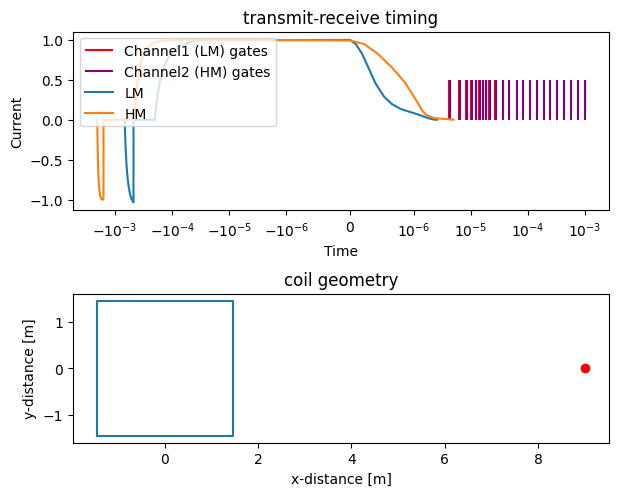

In [25]:
fig,axs=plt.subplots(2,1)
gex.plot(ax=axs[0])
axs[1].plot(tx.x, tx.y)
axs[1].plot(rx.x, rx.y, 'ro')
axs[1].set_aspect('equal')
axs[1].set_xlabel('x-distance [m]')
axs[1].set_ylabel('y-distance [m]')
axs[1].set_title('coil geometry')
axs[0].set_title('transmit-receive timing')
plt.tight_layout()

In [30]:
lmgates = torch.from_numpy(gex.gate_times('Channel1')[1:,0])
print(gex.gate_times(1))
hmgates = torch.from_numpy(gex.gate_times('Channel2')[1:,0])

LMwv = Waveform(gex.General['WaveformLMPoint'][:, 0], gex.General['WaveformLMPoint'][:, 1])
HMwv = Waveform(gex.General['WaveformHMPoint'][:, 0], gex.General['WaveformHMPoint'][:, 1])

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])

device = torch.device('cpu')
fwr = DualMoment(tx, rx, [lmgates.to(device), hmgates.to(device)], recfilters, [LMwv, HMwv])

[[4.1264e-06 3.3800e-06 5.0000e-06]
 [6.1442e-06 5.3800e-06 7.0000e-06]
 [8.1542e-06 7.3800e-06 9.0000e-06]
 [1.0161e-05 9.3800e-06 1.1000e-05]
 [1.2165e-05 1.1380e-05 1.3000e-05]
 [1.4168e-05 1.3380e-05 1.5000e-05]
 [1.6171e-05 1.5380e-05 1.7000e-05]
 [1.8173e-05 1.7380e-05 1.9000e-05]
 [2.1116e-05 1.7627e-05 2.5258e-05]
 [2.6931e-05 1.9993e-05 3.6163e-05]]


C:\Users\au487220\AppData\Local\Temp\ipykernel_13756\2658934028.py:1: DeprecationWarning: Passing a string in to channel is deprecated and will be removed in a future release.
Please change the function call to 'gate_times' to use only an integer
  lmgates = torch.from_numpy(gex.gate_times('Channel1')[1:,0])
C:\Users\au487220\AppData\Local\Temp\ipykernel_13756\2658934028.py:3: DeprecationWarning: Passing a string in to channel is deprecated and will be removed in a future release.
Please change the function call to 'gate_times' to use only an integer
  hmgates = torch.from_numpy(gex.gate_times('Channel2')[1:,0])


In [17]:
res = np.array([10, 200, 20])
thick1 = np.linspace(0.1, 5, 25)

In [18]:
sigma = torch.from_numpy(1./res)
thick = torch.tensor([5, 10])
data = fwr(sigma, thick)
print(data.shape)

torch.Size([31])


C:\Users\au487220\OneDrive - Aarhus universitet\Documents\Repositories\em1d\src\anemone\forwards\forwards.py:170: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at ..\aten\src\ATen\native\TensorShape.cpp:3679.)
  dbdts.append(dbdt.T)


In [19]:
thick_stack = np.vstack([thick1, np.ones_like(thick1)*10])
sigma = torch.from_numpy(1./res)[:, None]
thick = torch.from_numpy(thick_stack)
lgs = [plog.Log(np.log10(res), np.array([0, thk, thk+10]), np.array([thk,thk+10, 20]), 'rho', units='$\\Omega m$') for thk in thick1]

tensor([ 0.1000, 10.0000], dtype=torch.float64)
001	misfit:	3.30
002	misfit:	0.68
increased max step
003	misfit:	0.16

 3
tensor([ 0.3042, 10.0000], dtype=torch.float64)
001	misfit:	2.89
002	misfit:	0.58
increased max step
003	misfit:	0.17

 3
tensor([ 0.5083, 10.0000], dtype=torch.float64)
001	misfit:	2.52
002	misfit:	0.42

 2
tensor([ 0.7125, 10.0000], dtype=torch.float64)
001	misfit:	2.02
002	misfit:	0.24

 2
tensor([ 0.9167, 10.0000], dtype=torch.float64)
001	misfit:	1.69
002	misfit:	0.19

 2
tensor([ 1.1208, 10.0000], dtype=torch.float64)
001	misfit:	1.65
002	misfit:	0.22

 2
tensor([ 1.3250, 10.0000], dtype=torch.float64)
001	misfit:	1.59
002	misfit:	0.25

 2
tensor([ 1.5292, 10.0000], dtype=torch.float64)
001	misfit:	0.76
002	misfit:	0.31

 2
tensor([ 1.7333, 10.0000], dtype=torch.float64)
001	misfit:	0.75
002	misfit:	0.37

 2
tensor([ 1.9375, 10.0000], dtype=torch.float64)
001	misfit:	1.02
002	misfit:	0.42

 2
tensor([ 2.1417, 10.0000], dtype=torch.float64)
001	misfit:	1.74
002

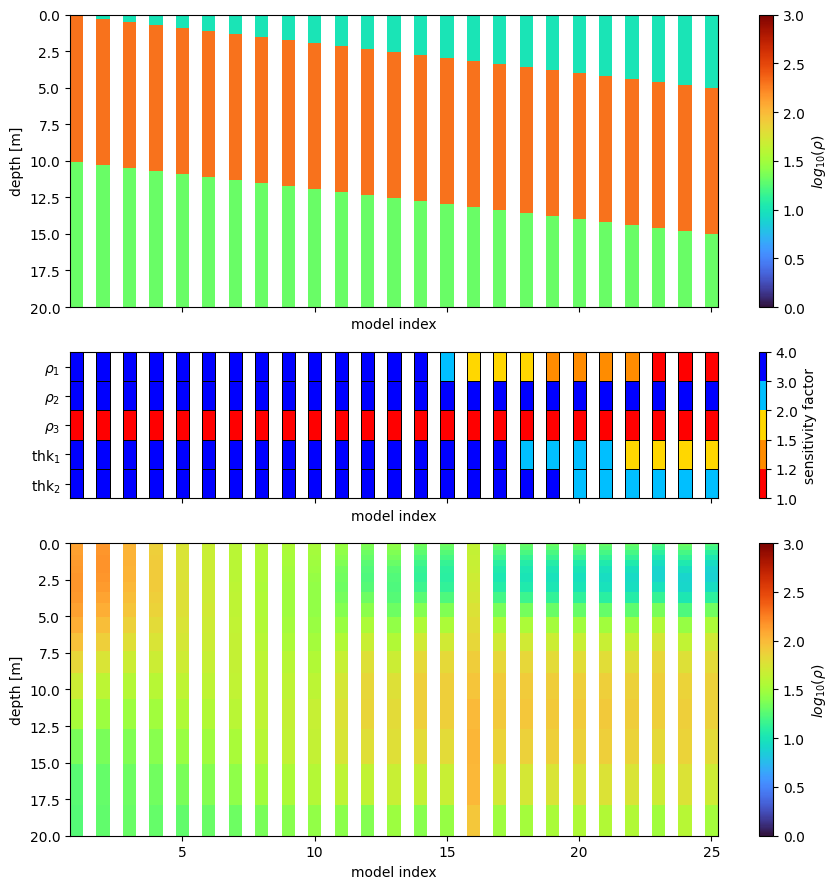

In [20]:
cm = plt.get_cmap('Spectral')

fig,axs = plt.subplots(3,1, sharex=True, figsize=(9,9), height_ratios=[2,1,2])
nanmat = np.zeros((2,2))
nanmat[:,:] = np.nan
tcat = torch.cat(fwr.times)
lm_slice = slice(0, len(fwr.times[0]))
hm_slice = slice(len(fwr.times[0]), None)

for i,lg in enumerate(lgs):
    sigma = torch.from_numpy(1./res)
    thick = torch.tensor([lg.depth_bot[0], 10])
    print(thick)
    dbdt = fwr(sigma, thick)
    
    dbdt_err = compute_relstd(tcat, dbdt, moment=3*9)
    dbdt_err[hm_slice] = compute_relstd(tcat, dbdt, moment=30*9)[hm_slice]


#    inv = Inversion(dbdt, dbdt*dbdt_err, cmdl, fwr)
    m_true = FewLayerModel(sigma, thick, device=gpu)

    ax,pcm=lg.plot(ax=axs[0], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[0].set_ylim(20,0)

    inv = Inversion(dbdt, dbdt*dbdt_err, m_true, fwr)
    inv.plot_sensitivity_analysis(ax=axs[1], x_offset=i*2, cbar=i==2)

    cmd_smooth = SmoothModel.starting_model(31, device=gpu)
    
    dbdt_with_noise = dbdt + torch.clamp(torch.randn(len(dbdt), device=gpu), -1,1)*dbdt*dbdt_err/2

    inv2 = Inversion(dbdt_with_noise, dbdt*dbdt_err, cmd_smooth, fwr, logger=print)
    rmod = inv2.invert(smoothness=10, iter_cap=20)
    sgm,thk = rmod.values
    clg2 = plog.Log.standard(np.log10(1/sgm.cpu().numpy()), np.cumsum(thk.cpu().numpy()), 'rho')
    ax,pcm=clg2.plot(ax=axs[2], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[2].set_ylim(20,0)
    
for ax in axs:
    ax.set_xlabel('model index')
    ax.set_xticks(range(8, 51, 10))
    ax.set_xticklabels(range(5,26,5))
ax = axs[0]
ax.set_ylabel('depth [m]')
axs[2].set_ylabel('depth [m]')
axs[1].set_ylim(5,0)

plt.colorbar(pcm, ax=axs[0], label='$log_{10}\\left(\\rho\\right)$', format='%.1f')
plt.colorbar(pcm, ax=axs[2], label='$log_{10}\\left(\\rho\\right)$', format='%.1f')

plt.tight_layout()

tensor([ 0.1000, 10.0000], dtype=torch.float64)
001	misfit:	3.26
002	misfit:	0.64
increased max step
003	misfit:	0.13

 3


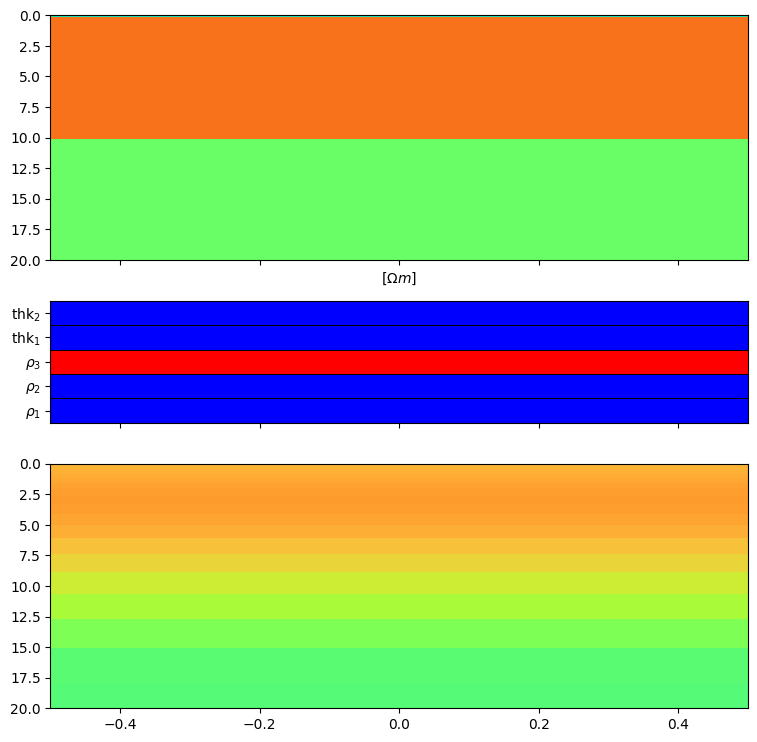

In [21]:
cm = plt.get_cmap('Spectral')

fig,axs = plt.subplots(3,1, sharex=True, figsize=(9,9), height_ratios=[2,1,2])
nanmat = np.zeros((2,2))
nanmat[:,:] = np.nan
tcat = torch.cat(fwr.times)
lm_slice = slice(0, len(fwr.times[0]))
hm_slice = slice(len(fwr.times[0]), None)

for i,lg in enumerate(lgs[:1]):
    sigma = torch.from_numpy(1./res)
    thick = torch.tensor([lg.depth_bot[0], 10])
    print(thick)
    dbdt = fwr(sigma, thick)
    
    dbdt_err = compute_relstd(tcat, dbdt, moment=3*9)
    dbdt_err[hm_slice] = compute_relstd(tcat, dbdt, moment=30*9)[hm_slice]


#    inv = Inversion(dbdt, dbdt*dbdt_err, cmdl, fwr)
    m_true = FewLayerModel(sigma, thick, device=gpu)

    ax,pcm=lg.plot(ax=axs[0], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[0].set_ylim(20,0)

    inv = Inversion(dbdt, dbdt*dbdt_err, m_true, fwr)
    inv.plot_sensitivity_analysis(ax=axs[1], x_offset=i*2, cbar=i==2)

    cmd_smooth = SmoothModel.starting_model(31, device=gpu)
    
    dbdt_with_noise = dbdt + torch.clamp(torch.randn(len(dbdt), device=gpu), -1,1)*dbdt*dbdt_err/2

    inv2 = Inversion(dbdt_with_noise, dbdt*dbdt_err, cmd_smooth, fwr, logger=print)
    rmod = inv2.invert(smoothness=10, iter_cap=20)
    sgm,thk = rmod.values
    clg2 = plog.Log.standard(np.log10(1/sgm.cpu().numpy()), np.cumsum(thk.cpu().numpy()), 'rho')
    ax,pcm=clg2.plot(ax=axs[2], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[2].set_ylim(20,0)
    